# Домашнее задание №6: классификация облачных структур

**Задача:** построить свёрточную нейронную сеть для сегментации четырёх типов организации облаков (`Fish`, `Flower`, `Gravel`, `Sugar`) на спутниковых изображениях.

Несмотря на слово «классификация» в названии, разметка содержит маски областей, поэтому решается задача **multi-label semantic segmentation**. Одно изображение может одновременно содержать несколько типов облаков. Для оценки используется коэффициент Dice.

## 1. Импорт библиотек и воспроизводимость

Ноутбук ожидает `data/train.csv` и каталог `data/train_images`. Если реальных данных нет, он использует маленький `smoke_data` только для технической проверки. Результат smoke-теста **нельзя считать итоговым качеством модели**.

In [1]:
from pathlib import Path
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, Dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch: {torch.__version__}; устройство: {DEVICE}')

PyTorch: 2.13.0+cpu; устройство: cpu


## 2. Параметры эксперимента

Оригинальные изображения имеют размер 1400×2100. Для уменьшения требований к памяти изображения и маски уменьшаются до 256×384. На GPU рекомендуется 20–30 эпох; early stopping завершит обучение раньше, если validation Dice перестанет улучшаться.

In [2]:
REAL_DATA_DIR = Path('data')
SMOKE_DATA_DIR = Path('smoke_data')
USE_REAL_DATA = (REAL_DATA_DIR / 'train.csv').is_file() and (REAL_DATA_DIR / 'train_images').is_dir()
DATA_DIR = REAL_DATA_DIR if USE_REAL_DATA else SMOKE_DATA_DIR

if not (DATA_DIR / 'train.csv').is_file():
    print('Kaggle-данные не найдены — создаю маленький smoke-датасет для проверки кода...')
    image_dir_demo = SMOKE_DATA_DIR / 'train_images'
    image_dir_demo.mkdir(parents=True, exist_ok=True)

    def encode_rle_demo(mask):
        pixels = (mask > 0).astype(np.uint8).reshape(-1, order='F')
        padded = np.concatenate(([0], pixels, [0]))
        changes = np.flatnonzero(padded[1:] != padded[:-1]) + 1
        changes[1::2] -= changes[::2]
        return ' '.join(map(str, changes))

    demo_rows = []
    demo_classes = ('Fish', 'Flower', 'Gravel', 'Sugar')
    demo_rng = np.random.default_rng(SEED)
    for image_index in range(6):
        image_name = f'smoke_{image_index:02d}.jpg'
        demo_image = demo_rng.integers(0, 256, size=(140, 210, 3), dtype=np.uint8)
        Image.fromarray(demo_image).save(image_dir_demo / image_name)
        for class_index, class_name in enumerate(demo_classes):
            demo_mask = np.zeros((1400, 2100), dtype=np.uint8)
            y, x = 100 + class_index * 220, 100 + image_index * 250
            demo_mask[y:y + 120, x:x + 180] = 1
            demo_rows.append({'Image_Label': f'{image_name}_{class_name}',
                              'EncodedPixels': encode_rle_demo(demo_mask)})
    pd.DataFrame(demo_rows).to_csv(SMOKE_DATA_DIR / 'train.csv', index=False)
    print('Smoke-датасет создан. Его метрики не являются результатом домашней работы.')

CLASSES = ('Fish', 'Flower', 'Gravel', 'Sugar')
ORIGINAL_SIZE = (1400, 2100)
IMAGE_SIZE = (256, 384) if USE_REAL_DATA else (32, 48)
BATCH_SIZE = 4 if USE_REAL_DATA else 2
EPOCHS = 30 if USE_REAL_DATA else 2
PATIENCE = 6
LEARNING_RATE = 1e-3
BASE_CHANNELS = 32 if USE_REAL_DATA else 4
ARTIFACT_DIR = Path('artifacts') if USE_REAL_DATA else Path('smoke_artifacts_not_for_submission')
ARTIFACT_DIR.mkdir(exist_ok=True)

mode = 'РЕАЛЬНЫЕ ДАННЫЕ' if USE_REAL_DATA else 'SMOKE-ТЕСТ (НЕ ДЛЯ ОЦЕНКИ КАЧЕСТВА)'
print(mode, '| data:', DATA_DIR, '| epochs:', EPOCHS, '| image size:', IMAGE_SIZE)

Kaggle-данные не найдены — создаю маленький smoke-датасет для проверки кода...


Smoke-датасет создан. Его метрики не являются результатом домашней работы.
SMOKE-ТЕСТ (НЕ ДЛЯ ОЦЕНКИ КАЧЕСТВА) | data: smoke_data | epochs: 2 | image size: (32, 48)


## 3. Подготовка разметки и декодирование RLE

В Kaggle маски хранятся в Run-Length Encoding. Нумерация начинается с 1 и идёт сверху вниз, затем слева направо, поэтому при восстановлении используется Fortran order.

In [3]:
def decode_rle(rle, height=1400, width=2100):
    if pd.isna(rle) or not str(rle).strip():
        return np.zeros((height, width), dtype=np.uint8)
    values = np.asarray(str(rle).split(), dtype=np.int64)
    starts = values[0::2] - 1
    lengths = values[1::2]
    flat = np.zeros(height * width, dtype=np.uint8)
    for start, length in zip(starts, lengths):
        flat[start:start + length] = 1
    return flat.reshape((height, width), order='F')

raw = pd.read_csv(DATA_DIR / 'train.csv')
parts = raw['Image_Label'].str.rsplit('_', n=1, expand=True)
raw[['image', 'label']] = parts
annotations = raw.pivot(index='image', columns='label', values='EncodedPixels').reindex(columns=CLASSES)
image_dir = DATA_DIR / 'train_images'
available = {path.name for path in image_dir.glob('*.jpg')}
image_names = sorted(set(annotations.index) & available)

print('Изображений:', len(image_names))
display(raw.head())
display(pd.DataFrame({'class': CLASSES, 'positive_masks': [annotations[c].notna().sum() for c in CLASSES]}))

Изображений: 6


,Image_Label,EncodedPixels,image,label
0,smoke_00.jpg_Fish,140101 120 141501 120 142901 120 144301 120 14...,smoke_00.jpg,Fish
1,smoke_00.jpg_Flower,140321 120 141721 120 143121 120 144521 120 14...,smoke_00.jpg,Flower
2,smoke_00.jpg_Gravel,140541 120 141941 120 143341 120 144741 120 14...,smoke_00.jpg,Gravel
3,smoke_00.jpg_Sugar,140761 120 142161 120 143561 120 144961 120 14...,smoke_00.jpg,Sugar
4,smoke_01.jpg_Fish,490101 120 491501 120 492901 120 494301 120 49...,smoke_01.jpg,Fish


,class,positive_masks
0,Fish,6
1,Flower,6
2,Gravel,6
3,Sugar,6


## 4. Dataset, аугментации и разбиение

Разбиение выполняется по уникальным изображениям в пропорции 80/20. Это исключает утечку одного изображения одновременно в train и validation. Для борьбы с переобучением используются случайные горизонтальные и вертикальные отражения.

In [4]:
class CloudDataset(Dataset):
    def __init__(self, names, augment=False):
        self.names = list(names)
        self.augment = augment

    def __len__(self):
        return len(self.names)

    def __getitem__(self, index):
        name = self.names[index]
        with Image.open(image_dir / name) as file:
            image = file.convert('RGB').resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.BILINEAR)
            image = np.asarray(image, dtype=np.float32) / 255.0

        masks = []
        for class_name in CLASSES:
            mask = decode_rle(annotations.loc[name, class_name], *ORIGINAL_SIZE)
            mask = Image.fromarray(mask).resize((IMAGE_SIZE[1], IMAGE_SIZE[0]), Image.Resampling.NEAREST)
            masks.append(np.asarray(mask, dtype=np.float32))
        masks = np.stack(masks, axis=-1)

        if self.augment and random.random() < 0.5:
            image, masks = np.flip(image, 1), np.flip(masks, 1)
        if self.augment and random.random() < 0.5:
            image, masks = np.flip(image, 0), np.flip(masks, 0)

        x = torch.from_numpy(np.ascontiguousarray(image.transpose(2, 0, 1)))
        y = torch.from_numpy(np.ascontiguousarray(masks.transpose(2, 0, 1)))
        return x, y, name

rng = np.random.default_rng(SEED)
rng.shuffle(image_names)
split = max(1, int(0.8 * len(image_names)))
train_names, val_names = image_names[:split], image_names[split:]
assert set(train_names).isdisjoint(val_names)

train_loader = DataLoader(CloudDataset(train_names, augment=True), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(CloudDataset(val_names), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print(f'Train: {len(train_names)}, validation: {len(val_names)}')

Train: 4, validation: 2


## 5. Архитектура U-Net

Encoder последовательно выделяет признаки и уменьшает разрешение. Decoder восстанавливает пространственное разрешение, используя skip connections из encoder. Последний слой возвращает четыре независимых logits-канала; softmax не применяется, поскольку классы могут пересекаться.

In [5]:
class DoubleConv(nn.Sequential):
    def __init__(self, in_channels, out_channels):
        super().__init__(
            nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), nn.ReLU(inplace=True),
        )

class UNet(nn.Module):
    def __init__(self, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = DoubleConv(3, base)
        self.e2 = DoubleConv(base, base * 2)
        self.e3 = DoubleConv(base * 2, base * 4)
        self.center = DoubleConv(base * 4, base * 8)
        self.u3 = nn.ConvTranspose2d(base * 8, base * 4, 2, 2)
        self.d3 = DoubleConv(base * 8, base * 4)
        self.u2 = nn.ConvTranspose2d(base * 4, base * 2, 2, 2)
        self.d2 = DoubleConv(base * 4, base * 2)
        self.u1 = nn.ConvTranspose2d(base * 2, base, 2, 2)
        self.d1 = DoubleConv(base * 2, base)
        self.head = nn.Conv2d(base, len(CLASSES), 1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        center = self.center(self.pool(e3))
        d3 = self.d3(torch.cat([e3, self.u3(center)], dim=1))
        d2 = self.d2(torch.cat([e2, self.u2(d3)], dim=1))
        d1 = self.d1(torch.cat([e1, self.u1(d2)], dim=1))
        return self.head(d1)

model = UNet(BASE_CHANNELS).to(DEVICE)
parameters = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Обучаемых параметров: {parameters:,}')

Обучаемых параметров: 30,556


## 6. Dice coefficient и функция потерь

Для масок $P$ и $T$: $Dice = \frac{2|P \cap T| + \varepsilon}{|P| + |T| + \varepsilon}$. В loss используется дифференцируемый soft Dice вместе с `BCEWithLogitsLoss`. Для метрики вероятности бинаризуются порогом 0.5. Если обе маски пусты, Dice равен 1.

In [6]:
class DiceBCELoss(nn.Module):
    def forward(self, logits, targets, eps=1e-7):
        bce = F.binary_cross_entropy_with_logits(logits, targets)
        probabilities = torch.sigmoid(logits)
        intersection = (probabilities * targets).sum(dim=(0, 2, 3))
        denominator = probabilities.sum(dim=(0, 2, 3)) + targets.sum(dim=(0, 2, 3))
        soft_dice = ((2 * intersection + eps) / (denominator + eps)).mean()
        return bce + (1 - soft_dice)

def hard_dice(logits, targets, eps=1e-7):
    predictions = (torch.sigmoid(logits) >= 0.5).float()
    intersection = (predictions * targets).sum(dim=(2, 3))
    denominator = predictions.sum(dim=(2, 3)) + targets.sum(dim=(2, 3))
    return (2 * intersection + eps) / (denominator + eps)  # B × C

criterion = DiceBCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)

## 7. Обучение с ранней остановкой

После каждой эпохи вычисляется validation Dice. При улучшении сохраняется checkpoint. Если метрика не улучшается `PATIENCE` эпох, обучение прекращается. Gradient clipping ограничивает норму градиента и снижает риск взрыва градиентов.

In [7]:
def run_epoch(loader, training):
    model.train(training)
    total_loss, total_count = 0.0, 0
    dice_rows = []
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for images, masks, _ in loader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, masks)
            if training:
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
            total_loss += loss.item() * len(images)
            total_count += len(images)
            dice_rows.append(hard_dice(logits, masks).detach().cpu())
    scores = torch.cat(dice_rows)
    return total_loss / total_count, scores.mean().item(), scores.mean(dim=0).tolist()

history = []
best_dice = -1.0
epochs_without_improvement = 0
checkpoint_path = ARTIFACT_DIR / 'best_model.pt'
start_time = time.time()

for epoch in range(1, EPOCHS + 1):
    train_loss, train_dice, _ = run_epoch(train_loader, training=True)
    val_loss, val_dice, class_dice = run_epoch(val_loader, training=False)
    scheduler.step(val_dice)
    row = {'epoch': epoch, 'train_loss': train_loss, 'val_loss': val_loss,
           'train_dice': train_dice, 'val_dice': val_dice,
           **{f'val_dice_{name.lower()}': score for name, score in zip(CLASSES, class_dice)}}
    history.append(row)
    print(f'Epoch {epoch:02d}: loss {train_loss:.4f}/{val_loss:.4f}; Dice {train_dice:.4f}/{val_dice:.4f}')

    if val_dice > best_dice + 1e-4:
        best_dice = val_dice
        epochs_without_improvement = 0
        torch.save({'epoch': epoch, 'val_dice': val_dice, 'model_state_dict': model.state_dict(),
                    'classes': CLASSES, 'image_size': IMAGE_SIZE}, checkpoint_path)
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= PATIENCE:
            print(f'Early stopping. Лучший validation Dice: {best_dice:.4f}')
            break

history = pd.DataFrame(history)
history.to_csv(ARTIFACT_DIR / 'history.csv', index=False)
print(f'Время обучения: {(time.time() - start_time) / 60:.1f} мин; лучший Dice: {best_dice:.4f}')

Epoch 01: loss 1.6595/1.6568; Dice 0.0150/0.0039


Epoch 02: loss 1.6533/1.6496; Dice 0.0160/0.0039
Время обучения: 0.0 мин; лучший Dice: 0.0039


## 8. Графики обучения и результаты по классам

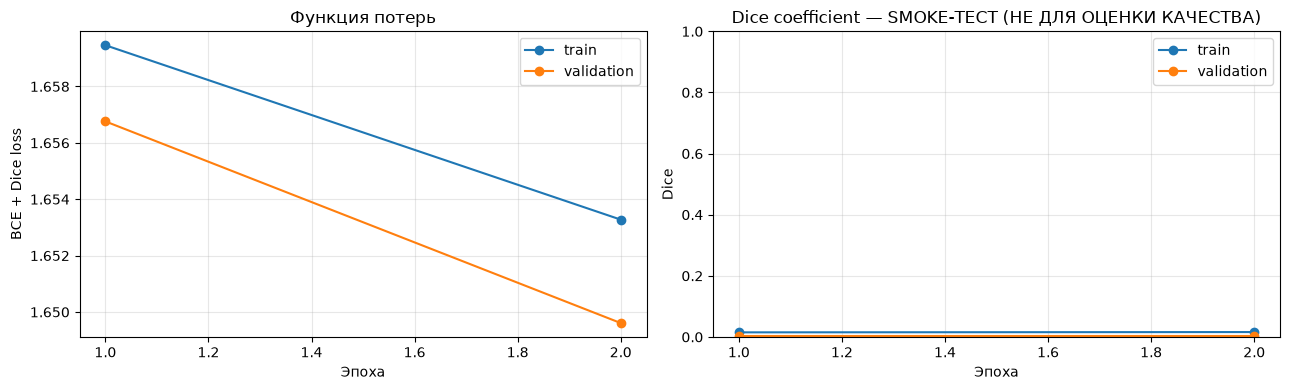

,Класс,Validation Dice
0,Fish,0.0000
1,Flower,0.0000
2,Gravel,0.0155
3,Sugar,0.0000


Лучший macro Dice: 0.0039, эпоха: 1


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(history.epoch, history.train_loss, marker='o', label='train')
axes[0].plot(history.epoch, history.val_loss, marker='o', label='validation')
axes[0].set(title='Функция потерь', xlabel='Эпоха', ylabel='BCE + Dice loss')
axes[1].plot(history.epoch, history.train_dice, marker='o', label='train')
axes[1].plot(history.epoch, history.val_dice, marker='o', label='validation')
axes[1].set(title=f'Dice coefficient — {mode}', xlabel='Эпоха', ylabel='Dice', ylim=(0, 1))
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'training_curves.png', dpi=160, bbox_inches='tight')
plt.show()

best = history.loc[history.val_dice.idxmax()]
class_results = pd.DataFrame({
    'Класс': CLASSES,
    'Validation Dice': [best[f'val_dice_{name.lower()}'] for name in CLASSES]
})
display(class_results.style.format({'Validation Dice': '{:.4f}'}))
print(f'Лучший macro Dice: {best.val_dice:.4f}, эпоха: {int(best.epoch)}')

## 9. Визуальная проверка предсказаний

Цвета: красный — Fish, зелёный — Flower, синий — Gravel, жёлтый — Sugar. Пересечения классов смешивают цвета.

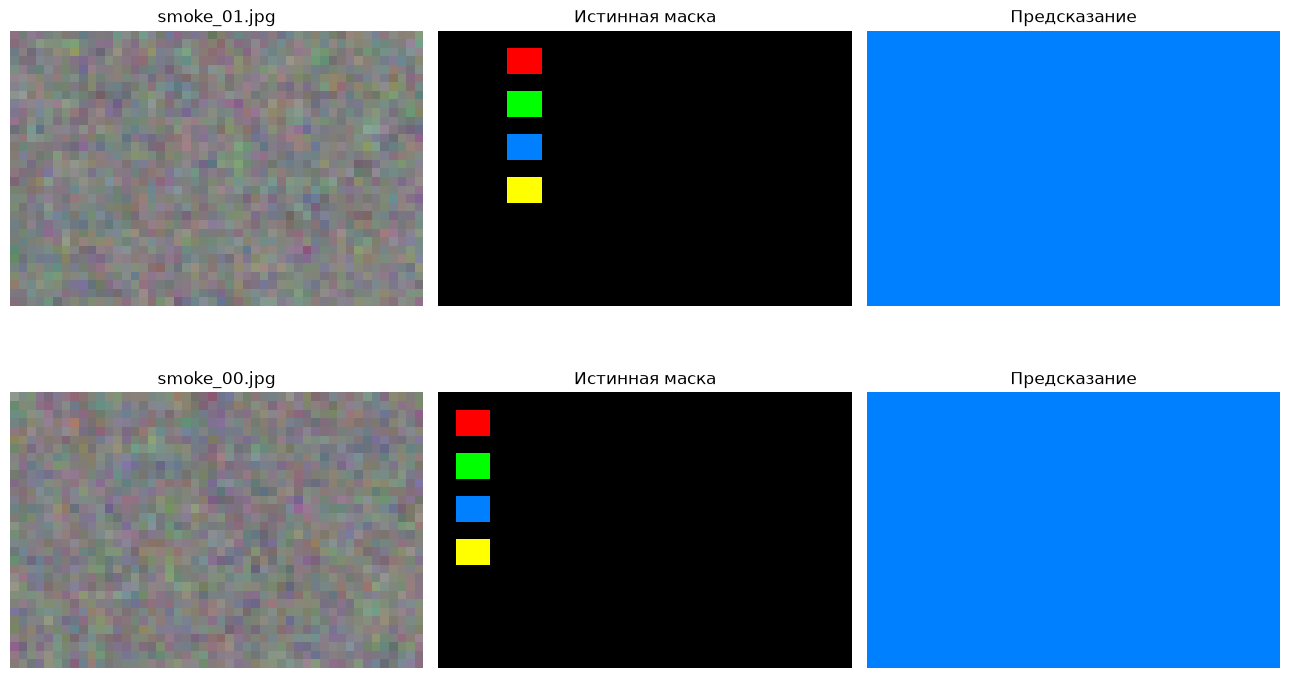

In [9]:
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
images, masks, names = next(iter(val_loader))
with torch.no_grad():
    predictions = (torch.sigmoid(model(images.to(DEVICE))).cpu() >= 0.5).float()

colors = np.array([[1, 0, 0], [0, 1, 0], [0, 0.5, 1], [1, 1, 0]])
count = min(2, len(images))
fig, axes = plt.subplots(count, 3, figsize=(13, 4 * count), squeeze=False)
for i in range(count):
    axes[i, 0].imshow(images[i].permute(1, 2, 0)); axes[i, 0].set_title(names[i])
    truth = np.tensordot(masks[i].permute(1, 2, 0).numpy(), colors, axes=1)
    pred = np.tensordot(predictions[i].permute(1, 2, 0).numpy(), colors, axes=1)
    axes[i, 1].imshow(np.clip(truth, 0, 1)); axes[i, 1].set_title('Истинная маска')
    axes[i, 2].imshow(np.clip(pred, 0, 1)); axes[i, 2].set_title('Предсказание')
    for ax in axes[i]: ax.axis('off')
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'predictions.png', dpi=160, bbox_inches='tight')
plt.show()

## 10. Выводы

1. Для задачи выбрана U-Net, так как требуется одновременно определить класс облачной структуры и локализовать её на изображении.
2. Совместное использование BCE и Dice loss учитывает как попиксельную ошибку, так и дисбаланс площадей классов.
3. Качество оценивается macro Dice по всем парам «изображение × класс».
4. Early stopping по validation Dice и аугментации уменьшают переобучение; gradient clipping защищает от взрыва градиентов.
5. Для содержательного анализа следует сравнить Dice классов: низкое значение конкретного класса может быть связано с редкостью класса, неоднозначными границами или большим разнообразием его формы.

**Важно:** итоговые численные выводы допустимы только при режиме `РЕАЛЬНЫЕ ДАННЫЕ`. Если выше указан `SMOKE-ТЕСТ`, необходимо добавить Kaggle-датасет и выполнить `Restart Kernel and Run All`.